# Remittance Project

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# World Bank, Personal Remittances, received (% of GDP)
remitt_df = pd.read_csv("wbremitt.csv", skiprows=4)

# Adolescents out of school (% of lower secondary...)
oos_df = pd.read_csv("oos.csv",skiprows=4)

# GDP per capita, PPP (current international $)
GDP_PPPdf= pd.read_csv("GDPPPP.csv", skiprows = 4)

# Population, total
POP_df = pd.read_csv("POP/POP.csv", skiprows=4)

# School enrollment, secondary (% gross)
gross_sec_df = pd.read_csv("gross_secenroll/grosssec.csv", skiprows = 4)

# Government expenditure on education, total (% of GDP)
govspend_df = pd.read_csv("GOVSpend/govspend.csv", skiprows = 4)

In [3]:
remitt_df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.815418,1.126929,1.023551,1.421505,1.240632,1.150685,1.039997,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.040153,1.210944,1.265702,1.288841,1.370416,1.520609,1.627284,1.968061,1.467600,NaN
2,Afghanistan,AFG,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.387093,4.450986,4.407428,3.953297,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.936272,4.828054,3.563084,3.179705,3.123878,3.268120,3.823394,5.504774,NaN,NaN
4,Angola,AGO,"Personal remittances, received (% of GDP)",BX.TRF.PWKR.DT.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,0.001656,0.001745,0.004244,0.013763,0.016135,0.010922,0.011379,0.049514,0.042334,NaN


In [4]:
# Remove the Unnamed: 70 which does not include any data, and melt remitt. Also drop indicator name and code, as they will be represented by value_name

remitt_df = remitt_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
remitt_long = pd.melt(remitt_df, id_vars=["Country Name", "Country Code"],value_name='remitt', var_name = "year" )

remitt_long['year'].unique()


<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [5]:
# repeat for each variable

oos_df = oos_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
oos_long = pd.melt(oos_df, id_vars=["Country Name", "Country Code"],value_name='out_of_school', var_name = "year" )

oos_long['year'].unique()


<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [6]:
GDP_PPPdf = GDP_PPPdf.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
GDP_long = pd.melt(GDP_PPPdf, id_vars=["Country Name", "Country Code"],value_name='gdp_ppp', var_name = "year" )

GDP_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [7]:
POP_df = POP_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
POP_long = pd.melt(POP_df, id_vars=["Country Name", "Country Code"],value_name='population', var_name = "year" )

POP_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [8]:
gross_sec_df = gross_sec_df.drop(columns=["Unnamed: 70", "Indicator Name", "Indicator Code"])
sec_enroll_long = pd.melt(gross_sec_df, id_vars=["Country Name", "Country Code"],value_name='secondary_enroll_gross', var_name = "year" )

sec_enroll_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [9]:
govspend_df = govspend_df.drop(columns=["Unnamed: 70","Indicator Name", "Indicator Code"])
gov_spend_long = pd.melt(govspend_df, id_vars=["Country Name", "Country Code"],value_name='gov_edu_spend', var_name = "year" )

gov_spend_long['year'].unique()

<ArrowStringArray>
['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
 '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
 '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
 '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
 '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
 '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
 '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
 '2023', '2024', '2025']
Length: 66, dtype: str

In [10]:
indexed = []
for i in [remitt_long, oos_long, GDP_long, POP_long, sec_enroll_long, gov_spend_long]:
    indexed.append(i.set_index(["Country Name", "Country Code", "year"]))

merged = pd.concat(indexed, axis=1)
merged = merged.reset_index()


In [11]:
merged["year"] = merged["year"].astype(int)

merged

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
0,Aruba,ABW,1960,NaN,NaN,NaN,54922.0,NaN,NaN
1,Africa Eastern and Southern,AFE,1960,NaN,NaN,NaN,130075728.0,NaN,NaN
2,Afghanistan,AFG,1960,NaN,NaN,NaN,9035043.0,NaN,NaN
3,Africa Western and Central,AFW,1960,NaN,NaN,NaN,97630925.0,NaN,NaN
4,Angola,AGO,1960,NaN,NaN,NaN,5231654.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17551,Kosovo,XKX,2025,17.309657,NaN,19263.326880,1576876.0,NaN,NaN
17552,"Yemen, Rep.",YEM,2025,NaN,NaN,NaN,41773878.0,NaN,NaN
17553,South Africa,ZAF,2025,0.235201,NaN,15905.679442,64747319.0,NaN,NaN
17554,Zambia,ZMB,2025,1.397257,NaN,4379.261310,21913874.0,NaN,NaN


In [12]:
merged.shape

(17556, 9)

In [13]:
# Separate Aggregates. From filtering in excel, they appear in metadata without a region, so can use the corresponding country codes to separate them.
aggregates = ['AFE','AFW','ARB','CEB','CSS','EAP','EAR','EAS','ECA','ECS','EMU','EUU','FCV','HIC','HPC','IBD','IBT','IDA','IDB','IDX','LAC','LCN','LDC','LIC','LMC','LMY','LTE',
              'MEA','MIC','MNA','NAC','OED','OSS','PRE','PSS','PST','SAS','SSA','SSF','SST','TEA','TEC','TLA','TMN','TSA','TSS','UMC','WLD','INX']

In [14]:
# Separate countries from aggregates:

is_agg = merged['Country Code'].isin(aggregates)

agg_df = merged[is_agg].copy()
countries_df = merged[~is_agg].copy()

In [15]:
agg_df

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
1,Africa Eastern and Southern,AFE,1960,NaN,NaN,NaN,1.300757e+08,NaN,NaN
3,Africa Western and Central,AFW,1960,NaN,NaN,NaN,9.763092e+07,NaN,NaN
7,Arab World,ARB,1960,NaN,NaN,NaN,9.154085e+07,NaN,NaN
36,Central Europe and the Baltics,CEB,1960,NaN,NaN,NaN,9.140131e+07,NaN,NaN
49,Caribbean small states,CSS,1960,NaN,NaN,NaN,2.558348e+06,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17528,"Middle East, North Africa, Afghanistan & Pakis...",TMN,2025,6.562889,NaN,11663.108856,7.484898e+08,NaN,NaN
17530,South Asia (IDA & IBRD),TSA,2025,4.538279,NaN,11562.185081,1.692253e+09,NaN,NaN
17531,Sub-Saharan Africa (IDA & IBRD countries),TSS,2025,NaN,NaN,5785.994856,1.321654e+09,NaN,NaN
17539,Upper middle income,UMC,2025,0.969141,5.9,25523.454203,3.078912e+09,NaN,NaN


In [16]:
countries_df.groupby("year").count().head(60)


,Country Name,Country Code,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
year,,,,,,,,
1960,217,217,0,0,0,216,0,0
1961,217,217,0,0,0,216,0,0
1962,217,217,0,0,0,216,0,0
1963,217,217,0,0,0,216,0,0
1964,217,217,0,0,0,216,0,0
1965,217,217,0,0,0,216,0,0
1966,217,217,0,0,0,216,0,0
1967,217,217,0,0,0,216,0,0
1968,217,217,0,0,0,216,0,0


In [17]:
countries_df.groupby('year').count().tail(6)

,Country Name,Country Code,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
year,,,,,,,,
2020,217,217,178,141,199,217,145,170
2021,217,217,176,146,199,217,148,168
2022,217,217,175,145,199,217,140,164
2023,217,217,173,143,197,217,147,121
2024,217,217,162,114,195,217,109,40
2025,217,217,131,12,185,217,9,2


In [18]:
# Restrict the years from 2000-2024. For two reasons. Before 1999, there are less than 25 countries each year with data for out of school adolescents, which is too small of a sample each year. Other variables saw large jumps too in 1999 and 2000 as well.
# 2000 aligns with the beginning of the Millennium Development Goals, which resulted in a new interest in collecting data in our countries of interest. So, 2000 is where we begin our analysis. 
# Data falls off in 2025. 
countries = countries_df[(countries_df['year'] >= 2000) & (countries_df['year'] < 2025)].copy()
agg = agg_df[(agg_df['year'] >= 2000) &(agg_df['year']<2025)].copy()
countries

,Country Name,Country Code,year,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
10640,Aruba,ABW,2000,0.057850,13.717770,30245.706973,90588.0,91.580200,4.71468
10642,Afghanistan,AFG,2000,NaN,NaN,813.550256,20130327.0,NaN,NaN
10644,Angola,AGO,2000,NaN,NaN,3689.537808,16194869.0,13.369070,2.60753
10645,Albania,ALB,2000,16.677034,5.856670,3977.793158,3089027.0,70.318649,3.33045
10646,Andorra,AND,2000,NaN,NaN,33458.118162,65685.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
17285,Kosovo,XKX,2024,17.287446,NaN,17890.360099,1594353.0,NaN,NaN
17286,"Yemen, Rep.",YEM,2024,NaN,NaN,NaN,40583164.0,NaN,NaN
17287,South Africa,ZAF,2024,0.213233,NaN,15478.645679,64007187.0,NaN,6.02110
17288,Zambia,ZMB,2024,1.321231,12.352050,4221.013971,21314956.0,56.788929,NaN


## Preliminary Analysis 
We suspect that as remittances increase, secondary school attendance should increase. We suspect this because the opportunity cost of not attending school falls as remittances increase, as remittances increase the incomes of households and reduce a household's dependence on nonschooling activities such as work, chores, early marriage, etc. 

In [19]:
country_means = countries.dropna(subset=['remitt', 'out_of_school']).groupby("Country Name")[['remitt', 'out_of_school', 'gdp_ppp', 'population', 'secondary_enroll_gross', 'gov_edu_spend']].mean()

country_means

,remitt,out_of_school,gdp_ppp,population,secondary_enroll_gross,gov_edu_spend
Country Name,,,,,,
Albania,10.967370,2.674769,14125.781877,2.681999e+06,94.854233,3.336275
Algeria,0.709140,4.454402,14546.507133,4.159835e+07,102.980669,6.593348
Andorra,1.298599,6.134220,64091.164554,7.911950e+04,98.556822,2.542124
Angola,0.028369,20.129878,7876.153430,2.600954e+07,31.706437,2.967028
Antigua and Barbuda,1.975869,1.707601,24432.115217,9.056900e+04,114.734001,2.482883
...,...,...,...,...,...,...
Viet Nam,4.237331,10.224973,2808.273537,7.796520e+07,NaN,NaN
West Bank and Gaza,14.076126,8.436002,4581.585406,3.961260e+06,87.553103,5.120735
"Yemen, Rep.",8.678328,43.167859,3257.425838,2.915250e+07,41.610033,NaN


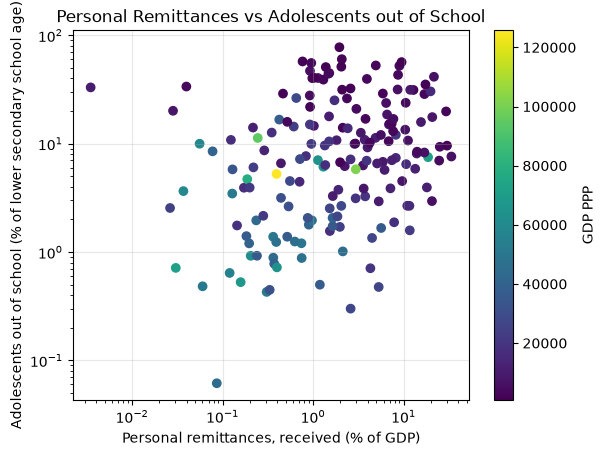

In [20]:
plt.scatter(country_means['remitt'], country_means['out_of_school'], c=country_means['gdp_ppp'])
plt.colorbar(label = 'GDP PPP')
plt.grid(alpha=0.3)
plt.xlabel('Personal remittances, received (% of GDP)')
plt.ylabel('Adolescents out of school (% of lower secondary school age)')
plt.title('Personal Remittances vs Adolescents out of School')
plt.xscale('log')
plt.yscale('log')
plt.show()


In [21]:
print(country_means[['remitt', 'out_of_school', 'gdp_ppp']].corr())
print(country_means[['remitt', 'out_of_school', 'gdp_ppp']].corr(method='spearman'))

                 remitt  out_of_school   gdp_ppp
remitt         1.000000       0.077079 -0.331933
out_of_school  0.077079       1.000000 -0.491338
gdp_ppp       -0.331933      -0.491338  1.000000
                 remitt  out_of_school   gdp_ppp
remitt         1.000000       0.292137 -0.512677
out_of_school  0.292137       1.000000 -0.764143
gdp_ppp       -0.512677      -0.764143  1.000000


This preliminary analysis does not do much to show us how changes in remittances correlate with changes in out of school rates for adolescents. This is largely because we are relying on averages, and do not control for income. This scatter plot only tells us that poor countries tend to have higher out of school rates and remittances. Our question has not yet been satisfied, but it does give us insights into what we need to control for. Using the world bank meta data, the next step is to control for country income status. We can also look at within country changes (deviations from the 25 year average) as another mechanism for determining relationships between our variables of interest.